<a href="https://colab.research.google.com/github/prince-pokharna/MachineLearningTutorials/blob/main/SVM(non_linear).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [11]:
df = pd.read_csv("used_device_data.csv")
df = df.dropna()

# Let's inspect column names to find the exact matches for memory and camera
print("Columns in dataset:", df.columns.tolist())

# Map common column name variations automatically
col_mapping = {}
for col in df.columns:
    col_lower = col.lower()
    if 'ram' in col_lower:
        col_mapping['ram'] = col
    elif 'battery' in col_lower:
        col_mapping['battery'] = col
    elif 'mem' in col_lower or 'int_memory' in col_lower:
        col_mapping['int_memory'] = col
    elif 'screen' in col_lower:
        col_mapping['screen_size'] = col
    elif 'cam' in col_lower:
        col_mapping['main_camera_mp'] = col

# Select the mapped names or fallback to defaults
ram_col = col_mapping.get('ram', 'ram')
battery_col = col_mapping.get('battery', 'battery')
int_mem_col = col_mapping.get('int_memory', 'int_memory')
screen_col = col_mapping.get('screen_size', 'screen_size')
camera_col = col_mapping.get('main_camera_mp', 'main_camera_mp')

median_price = df["normalized_used_price"].median()
df["expensive"] = (df["normalized_used_price"] > median_price).astype(int)

features = [ram_col, battery_col, int_mem_col, screen_col, camera_col]
print("Using features:", features)

X = df[features]
y = df["expensive"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

Columns in dataset: ['device_brand', 'os', 'screen_size', '4g', '5g', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used', 'normalized_used_price', 'normalized_new_price']
Using features: ['ram', 'battery', 'internal_memory', 'screen_size', 'front_camera_mp']


In [12]:
model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

In [13]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Cheap", "Expensive"]))

Accuracy: 0.8249

Classification Report:
              precision    recall  f1-score   support

       Cheap       0.82      0.84      0.83       325
   Expensive       0.83      0.81      0.82       326

    accuracy                           0.82       651
   macro avg       0.83      0.82      0.82       651
weighted avg       0.83      0.82      0.82       651



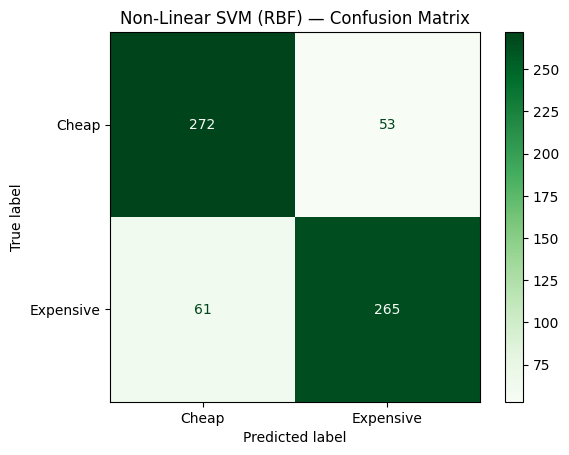

In [14]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Cheap", "Expensive"])
disp.plot(cmap="Greens")
plt.title("Non-Linear SVM (RBF) — Confusion Matrix")
plt.show()

In [16]:
for c_val in [0.1, 1, 10, 100]:
    m = SVC(kernel='rbf', C=c_val, gamma='scale', random_state=42)
    m.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, m.predict(X_test_scaled))
    print(f"C={c_val:5} → Accuracy: {acc:.4f}")

C=  0.1 → Accuracy: 0.8203
C=    1 → Accuracy: 0.8249
C=   10 → Accuracy: 0.8264
C=  100 → Accuracy: 0.8387


In [15]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

results = {
    "Linear SVM": SVC(kernel='linear', random_state=42),
    "RBF SVM":    SVC(kernel='rbf',    random_state=42)
}

for name, clf in results.items():
    clf.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, clf.predict(X_test_scaled))
    print(f"{name}: {acc:.4f}")

Linear SVM: 0.8203
RBF SVM: 0.8249
